## Hyperparameter Tuning in SageMaker

In [1]:
import sagemaker
from sagemaker.core.helper.session_helper import Session, get_execution_role
from sagemaker.train.tuner import HyperparameterTuner
from sagemaker.core.parameter import (
    IntegerParameter,
    CategoricalParameter,
    ContinuousParameter,
)

sagemaker_session = Session()

bucket = sagemaker_session.default_bucket()
prefix = "course3/lesson3/hyperparameter-tuning/DEMO-pytorch-cifar"

role = get_execution_role()

sagemaker.config INFO - Not applying SDK defaults from location: /etc/xdg/sagemaker/config.yaml
sagemaker.config INFO - Not applying SDK defaults from location: /home/sagemaker-user/.config/sagemaker/config.yaml


In [2]:
from torchvision.datasets import CIFAR10
from torchvision import transforms


local_dir = 'cifar_data'
# CIFAR10.mirrors = ["https://sagemaker-sample-files.s3.amazonaws.com/datasets/image/CIFAR10/"]
CIFAR10(
    local_dir,
    download=False,
    transform=transforms.Compose(
        [transforms.ToTensor()]
    )
)

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: cifar_data
    Split: Train
    StandardTransform
Transform: Compose(
               ToTensor()
           )

In [3]:
# Upload the data to an S3 bucket
inputs = sagemaker_session.upload_data(path=local_dir, bucket=bucket, key_prefix=prefix)
print("input spec (in this case, just an S3 path): {}".format(inputs))

input spec (in this case, just an S3 path): s3://sagemaker-us-east-1-950885994135/course3/lesson3/hyperparameter-tuning/DEMO-pytorch-cifar


In [4]:
from sagemaker.train import ModelTrainer
from sagemaker.train.configs import Compute, SourceCode
from sagemaker.core import image_uris

image_uri = image_uris.retrieve(
    framework="pytorch",
    region=sagemaker_session.boto_region_name,
    version="1.8",
    py_version="py36",
    image_scope="training",
    instance_type="ml.m5.large"
)

trainer = ModelTrainer(
    training_image=image_uri,
    role=role,
    compute=Compute(instance_type="ml.m5.large", instance_count=1),
    source_code=SourceCode(source_dir=".", entry_script="cifar.py")
)

[10/19/26 08:56:25] INFO     SageMaker session not provided. Using default Session.                  ]8;id=2675915;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=2675916;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#61\61]8;;\

                    INFO     Base name not provided. Using default name:                             ]8;id=2675922;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=2675923;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#90\90]8;;\
                             pytorch-training-job                                                                  

                    INFO     StoppingCondition not provided. Using default:                         ]8;id=2675929;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=2675930;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#128\128]8;;\
                             max_runtime_in_seconds=3600 max_wait_time_in_seconds=None                             
                             max_pending_time_in_seconds=None                                                      

                    INFO     OutputDataConfig not provided. Using default:                          ]8;id=2675936;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py\defaults.py]8;;\:]8;id=2675937;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/defaults.py#153\153]8;;\
                             s3_output_path='s3://sagemaker-us-east-1-950885994135/pytorch-training                
                             -job' kms_key_id=None compression_type='GZIP'                                         

                    INFO     Training image URI:                                               ]8;id=2675944;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py\model_trainer.py]8;;\:]8;id=2675945;file:///opt/conda/lib/python3.12/site-packages/sagemaker/train/model_trainer.py#558\558]8;;\
                             763104351884.dkr.ecr.us-east-1.amazonaws.com/pytorch-training:1.8                     
                             -cpu-py36                                                                             

In [5]:
hyperparameter_ranges = {
    "lr": ContinuousParameter(0.001, 0.1),
    "batch-size": CategoricalParameter([32, 64, 128]),
    "epochs": IntegerParameter(2, 4)
}

In [6]:
objective_metric_name = "average test loss"
objective_type = "Minimize"
metric_definitions = [{"Name": "average test loss", "Regex": "Test set: Average loss: ([0-9\\.]+)"}]

In [7]:
tuner = HyperparameterTuner(
    model_trainer=trainer,
    objective_metric_name=objective_metric_name,
    hyperparameter_ranges=hyperparameter_ranges,
    metric_definitions=metric_definitions,
    objective_type=objective_type,
    max_jobs=4,
    max_parallel_jobs=2
)

In [8]:
from sagemaker.train.configs import InputData

# Hyperparameter tuning
tuner.tune(
    inputs=[InputData(channel_name="training", data_source=inputs)]
)

[10/19/26 08:56:42] INFO     Creating hyper_parameter_tuning_job resource.                       ]8;id=2675952;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=2675953;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#14972\14972]8;;\

Output()

[10/19/26 09:03:28] INFO     Final Resource Status: Completed                                    ]8;id=2675959;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=2675960;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#15201\15201]8;;\

In [9]:
import boto3
from sagemaker.core import image_uris
from sagemaker.serve import ModelBuilder

# 1. Get the name of the best training job from the tuner
best_job_name = tuner.best_training_job()
print(f"Best training job: {best_job_name}")

Best training job: pytorch-training-261019-0856-002-96959a13


In [10]:
# 2. Retrieve the S3 model data URL for that specific job
sm_client = boto3.client("sagemaker")
job_info = sm_client.describe_training_job(TrainingJobName=best_job_name)
model_data_url = job_info["ModelArtifacts"]["S3ModelArtifacts"]
print(f"Model artifact located at: {model_data_url}")

Model artifact located at: s3://sagemaker-us-east-1-950885994135/pytorch-training-job/pytorch-training-261019-0856-002-96959a13/output/model.tar.gz


In [11]:
# 3. Retrieve the correct PyTorch inference image for CPU
inference_image_uri = image_uris.retrieve(
    framework="pytorch",
    region=sagemaker_session.boto_region_name,
    version="1.8",
    py_version="py36",
    image_scope="inference",
    instance_type="ml.m5.large"
)

In [13]:
# 4. Repack model.tar.gz so cifar.py lives in code/ inside the model archive.
# The PyTorch >=1.6 inference containers only load user code from model.tar.gz/code/.
# They do NOT download SAGEMAKER_SUBMIT_DIRECTORY, so without this step the container
# falls back to default_model_fn (torch.jit.load) and the worker crashes on load.
import os
import shutil
import tarfile

s3 = boto3.client("s3")
src_bucket, src_key = model_data_url.replace("s3://", "").split("/", 1)
s3.download_file(src_bucket, src_key, "model.tar.gz")

shutil.rmtree("repack", ignore_errors=True)
os.makedirs("repack/code")
with tarfile.open("model.tar.gz") as t:
    t.extractall("repack", filter="data")                      # -> repack/model.pth
shutil.copy("cifar.py", "repack/code/cifar.py")  # -> repack/code/cifar.py

with tarfile.open("model_with_code.tar.gz", "w:gz") as t:
    for name in os.listdir("repack"):
        t.add(os.path.join("repack", name), arcname=name)

# Sanity check: should list model.pth and code/cifar.py
with tarfile.open("model_with_code.tar.gz") as t:
    print(t.getnames())

model_with_code_url = sagemaker_session.upload_data(
    path="model_with_code.tar.gz", bucket=bucket, key_prefix=f"{prefix}/model-with-code"
)
print(f"Repacked model artifact: {model_with_code_url}")


['code', 'code/cifar.py', 'model.pth']
Repacked model artifact: s3://sagemaker-us-east-1-950885994135/course3/lesson3/hyperparameter-tuning/DEMO-pytorch-cifar/model-with-code/model_with_code.tar.gz


In [14]:
# 5. Build the model from the repacked archive
builder = ModelBuilder(
    model_path=model_with_code_url,
    image_uri=inference_image_uri,
    role_arn=role,
    env_vars={
        "SAGEMAKER_PROGRAM": "cifar.py",  # required: the toolkit's default module name is inference.py
    },
)

model = builder.build()


[10/19/26 09:06:30] DEBUG    Auto-detecting optimal instance type for model...           ]8;id=2675975;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=2675976;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#340\340]8;;\

                    DEBUG    Using default CPU instance type: ml.m5.large                ]8;id=2675982;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=2675983;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#374\374]8;;\

                    INFO     SageMaker Python SDK will collect telemetry to help us better ]8;id=2675990;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/telemetry/telemetry_logging.py\telemetry_logging.py]8;;\:]8;id=2675991;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/telemetry/telemetry_logging.py#322\322]8;;\
                             understand our user's needs, diagnose issues, and deliver                             
                             additional features.                                                                  
                             To opt out of telemetry, please disable via TelemetryOptOut                           
                             parameter in SDK defaults config. For more information, refer                         
                             to                                                                                    
                             https://sagemaker.readthedocs.io/en/stable/overview.html#conf                         
                             iguring-and-using-defaults-with-the-sagemaker-python-sdk.                             

                    DEBUG    No ModelMetadata provided. ModelBuilder is not handling    ]8;id=2675997;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=2675998;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#1335\1335]8;;\
                             MLflow model input                                                                    

                    INFO     Creating model with name: model-3df502df                        ]8;id=2676005;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=2676006;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1922\1922]8;;\

[10/19/26 09:06:31] INFO     ✅ Model has been created: 'model-3df502df' using server None in ]8;id=2676013;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py\model_builder.py]8;;\:]8;id=2676014;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py#3357\3357]8;;\
                             SAGEMAKER_ENDPOINT mode (ARN:                                                         
                             arn:aws:sagemaker:us-east-1:950885994135:model/model-3df502df)                        

In [15]:
# 6. Deploy. After this, check CloudWatch: there should be no "default_model_fn"
# or "Backend worker process died" messages.
predictor = builder.deploy(initial_instance_count=1, instance_type="ml.m5.large")


[10/19/26 09:06:37] INFO     Creating endpoint-config with name endpoint-bf03948d            ]8;id=2676020;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=2676021;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1093\1093]8;;\

                    INFO     Creating endpoint with name endpoint-bf03948d                   ]8;id=2676027;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=2676028;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1125\1125]8;;\

                    WARNING  Failed to enable live logging: An error occurred                ]8;id=2676034;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=2676035;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#2844\2844]8;;\
                             (AccessDeniedException) when calling the FilterLogEvents                              
                             operation: User:                                                                      
                             arn:aws:sts::950885994135:assumed-role/AmazonSageMaker-Executio                       
                             nRole-20261013T173018/SageMaker is not authorized to perform:                         
                             logs:FilterLogEvents on resource:                                                     
                             arn:aws:logs:us-east-1:950885994135:log-group:/aws/sagemaker/En                       
                             dpoints/endpoint-bf03948d because no identity-based policy                            
                             allows the logs:FilterLogEvents action. Fallback to default                           
                             logging...                                                                            

Output()

[10/19/26 09:10:08] INFO     ✅ Deployment successful: Endpoint 'endpoint-bf03948d' using     ]8;id=2676041;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py\model_builder.py]8;;\:]8;id=2676042;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py#2687\2687]8;;\
                             None in SAGEMAKER_ENDPOINT mode (ARN:                                                 
                             arn:aws:sagemaker:us-east-1:950885994135:endpoint/endpoint-bf039                      
                             48d)                                                                                  

## Query the Endpoint

In [40]:
import gzip 
import numpy as np
import random
import os

file = 'cifar_data/cifar-10-batches-py/data_batch_1'
def unpickle(file):
    import pickle
    with open(file, 'rb') as fo:
        dict = pickle.load(fo, encoding='bytes')
    return dict

data=unpickle(file)
true_label=data[b'labels'][1]
data=np.reshape(data[b'data'][1], (3, 32, 32))
data.shape

(3, 32, 32)

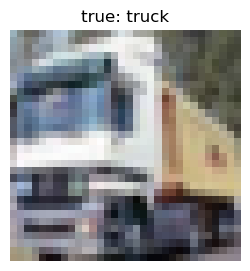

In [41]:
import matplotlib.pyplot as plt

classes = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]

img = data.transpose(1, 2, 0)          # (3, 32, 32) -> (32, 32, 3)

plt.figure(figsize=(3, 3))
plt.imshow(img, interpolation="nearest")
plt.title(f"true: {classes[true_label]}")
plt.axis("off")
plt.show()

In [43]:
import json
import numpy as np

# The model expects (N, 3, 32, 32) float inputs in [0, 1] (training used ToTensor()).
# The raw pickle data is uint8 in [0, 255] with no batch dimension, so fix both.
payload = np.expand_dims(data, axis=0).astype("float32") / 255.0   # (1, 3, 32, 32)

# Query the endpoint
response = predictor.invoke(
    body=json.dumps(payload.tolist()),
    content_type="application/json",
)

body = response.body.read().decode("utf-8")   # read once
print(body)
print("------------------------------------")

log_probs = np.array(json.loads(body))
classes = ["airplane", "automobile", "bird", "cat", "deer",
           "dog", "frog", "horse", "ship", "truck"]
pred = int(log_probs.argmax(axis=1)[0])
print(f"predicted: {classes[pred]} | true: {classes[true_label]}")


[[-5.247395038604736, -4.80617094039917, -8.676918029785156, -8.396928787231445, -11.317910194396973, -9.468805313110352, -9.942152976989746, -8.02187728881836, -2.490175247192383, -0.1022515594959259]]
------------------------------------
predicted: truck | true: truck


### Cleanup

After you have finished with this exercise, remember to delete the prediction endpoint to release the instance associated with it

In [46]:
predictor.delete()

[10/19/26 09:35:50] INFO     Deleting Endpoint - endpoint-9e4a1ba3                               ]8;id=2676102;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py\resources.py]8;;\:]8;id=2676103;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/resources.py#10427\10427]8;;\

## Find the best training job and deploy endpoint in case the kernel died during training job

In [18]:
# import boto3
# import os
# import shutil
# import tarfile
# import json
# from sagemaker.core.helper.session_helper import Session, get_execution_role
# from sagemaker.core import image_uris
# from sagemaker.serve import ModelBuilder

# # ── Session ────────────────────────────────────────────────────────────────────
# sagemaker_session = Session()
# sm = boto3.client("sagemaker")
# role = get_execution_role()
# bucket = sagemaker_session.default_bucket()
# prefix = "course3/lesson3/hyperparameter-tuning/DEMO-pytorch-cifar"

In [20]:
# # ── 1. Find the most recent completed tuning job ───────────────────────────────
# tuning_jobs = sm.list_hyper_parameter_tuning_jobs(
#     SortBy="CreationTime",
#     SortOrder="Descending",
#     MaxResults=5,
# )["HyperParameterTuningJobSummaries"]

# print("Recent tuning jobs:")
# for j in tuning_jobs:
#     print(f"  {j['HyperParameterTuningJobName']}  |  {j['HyperParameterTuningJobStatus']}")

# # Pick the most recent completed one
# tuning_job = next(
#     j for j in tuning_jobs if j["HyperParameterTuningJobStatus"] == "Completed"
# )
# tuning_job_name = tuning_job["HyperParameterTuningJobName"]
# print(f"\nUsing tuning job: {tuning_job_name}")

Recent tuning jobs:
  pytorch-training-261019-0856  |  Completed
  pytorch-training-261019-0829  |  Completed
  pytorch-training-261019-0753  |  Completed
  pytorch-training-261018-2045  |  Completed
  pytorch-training-261018-2038  |  Completed

Using tuning job: pytorch-training-261019-0856


In [21]:
# # ── 2. Get the best training job and its hyperparameters ───────────────────────
# tuning_info = sm.describe_hyper_parameter_tuning_job(
#     HyperParameterTuningJobName=tuning_job_name
# )
# best = tuning_info["BestTrainingJob"]
# best_job_name = best["TrainingJobName"]
# best_hps      = best["TunedHyperParameters"]
# best_metric   = best["FinalHyperParameterTuningJobObjectiveMetric"]

# print(f"\nBest training job : {best_job_name}")
# print(f"Best hyperparameters:")
# for k, v in best_hps.items():
#     print(f"  {k}: {v}")
# print(f"Best metric — {best_metric['MetricName']}: {best_metric['Value']:.4f}")


Best training job : pytorch-training-261019-0856-002-96959a13
Best hyperparameters:
  batch-size: 32
  epochs: 4
  lr: 0.0608145942043355
Best metric — average test loss: 1.2899


In [22]:
# # ── 3. Get the model artifact and training image ───────────────────────────────
# job_info        = sm.describe_training_job(TrainingJobName=best_job_name)
# model_data_url  = job_info["ModelArtifacts"]["S3ModelArtifacts"]
# print(f"\nModel artifact: {model_data_url}")

# inference_image_uri = image_uris.retrieve(
#     framework="pytorch",
#     region=sagemaker_session.boto_region_name,
#     version="1.8",
#     py_version="py36",
#     image_scope="inference",
#     instance_type="ml.t3.medium",
# )


Model artifact: s3://sagemaker-us-east-1-950885994135/pytorch-training-job/pytorch-training-261019-0856-002-96959a13/output/model.tar.gz


In [23]:
# # ── 4. Repack model.tar.gz to include cifar.py under code/ ────────────────────
# s3 = boto3.client("s3")
# src_bucket, src_key = model_data_url.replace("s3://", "").split("/", 1)
# s3.download_file(src_bucket, src_key, "model.tar.gz")

# shutil.rmtree("repack", ignore_errors=True)
# os.makedirs("repack/code")
# with tarfile.open("model.tar.gz") as t:
#     t.extractall("repack", filter="data")
# shutil.copy("cifar.py", "repack/code/cifar.py")

# with tarfile.open("model_with_code.tar.gz", "w:gz") as t:
#     for name in os.listdir("repack"):
#         t.add(os.path.join("repack", name), arcname=name)

# with tarfile.open("model_with_code.tar.gz") as t:
#     print(f"\nArchive contents: {t.getnames()}")

# model_with_code_url = sagemaker_session.upload_data(
#     path="model_with_code.tar.gz", bucket=bucket, key_prefix=f"{prefix}/model-with-code"
# )
# print(f"Repacked artifact: {model_with_code_url}")


Archive contents: ['code', 'code/cifar.py', 'model.pth']
Repacked artifact: s3://sagemaker-us-east-1-950885994135/course3/lesson3/hyperparameter-tuning/DEMO-pytorch-cifar/model-with-code/model_with_code.tar.gz


In [24]:
# # ── 5. Build and deploy ────────────────────────────────────────────────────────
# builder = ModelBuilder(
#     model_path=model_with_code_url,
#     image_uri=inference_image_uri,
#     role_arn=role,
#     env_vars={"SAGEMAKER_PROGRAM": "cifar.py"},
# )
# model = builder.build()
# predictor = builder.deploy(initial_instance_count=1, instance_type="ml.t3.medium")
# print(f"\nEndpoint is live: {predictor.endpoint_name}")

[10/19/26 09:22:05] DEBUG    Auto-detecting optimal instance type for model...           ]8;id=2676047;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=2676048;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#340\340]8;;\

                    DEBUG    Using default CPU instance type: ml.m5.large                ]8;id=2676053;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=2676054;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#374\374]8;;\

                    DEBUG    No ModelMetadata provided. ModelBuilder is not handling    ]8;id=2676059;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py\model_builder_utils.py]8;;\:]8;id=2676060;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder_utils.py#1335\1335]8;;\
                             MLflow model input                                                                    

                    INFO     Creating model with name: model-6bf3b65d                        ]8;id=2676065;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=2676066;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1922\1922]8;;\

[10/19/26 09:22:06] INFO     ✅ Model has been created: 'model-6bf3b65d' using server None in ]8;id=2676071;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py\model_builder.py]8;;\:]8;id=2676072;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py#3357\3357]8;;\
                             SAGEMAKER_ENDPOINT mode (ARN:                                                         
                             arn:aws:sagemaker:us-east-1:950885994135:model/model-6bf3b65d)                        

...

                    INFO     Creating endpoint with name endpoint-9e4a1ba3                   ]8;id=2676083;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=2676084;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#1125\1125]8;;\

[10/19/26 09:22:07] WARNING  Failed to enable live logging: An error occurred                ]8;id=2676089;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py\session_helper.py]8;;\:]8;id=2676090;file:///opt/conda/lib/python3.12/site-packages/sagemaker/core/helper/session_helper.py#2844\2844]8;;\
                             (AccessDeniedException) when calling the FilterLogEvents                              
                             operation: User:                                                                      
                             arn:aws:sts::950885994135:assumed-role/AmazonSageMaker-Executio                       
                             nRole-20261013T173018/SageMaker is not authorized to perform:                         
                             logs:FilterLogEvents on resource:                                                     
                             arn:aws:logs:us-east-1:950885994135:log-group:/aws/sagemaker/En                       
                             dpoints/endpoint-9e4a1ba3 because no identity-based policy                            
                             allows the logs:FilterLogEvents action. Fallback to default                           
                             logging...                                                                            

Output()

[10/19/26 09:25:37] INFO     ✅ Deployment successful: Endpoint 'endpoint-9e4a1ba3' using     ]8;id=2676095;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py\model_builder.py]8;;\:]8;id=2676096;file:///opt/conda/lib/python3.12/site-packages/sagemaker/serve/model_builder.py#2687\2687]8;;\
                             None in SAGEMAKER_ENDPOINT mode (ARN:                                                 
                             arn:aws:sagemaker:us-east-1:950885994135:endpoint/endpoint-9e4a1                      
                             ba3)                                                                                  


Endpoint is live: endpoint-9e4a1ba3
